# Proyek Analisis Data: E-Commerce Public Dataset (Olist, Brasil)
- **Nama:** Catherine
- **Email:** catherine100706@gmail.com
- **ID Dicoding:** [Input Username]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam:
**S**pecific, **M**easurable, **A**ction-oriented, **R**elevant, dan **T**ime-bound.

Seluruh analisis dibatasi pada **pesanan berstatus `delivered` dengan tanggal pembelian 1 Januari 2017 – 31 Agustus 2018** (20 bulan penuh). Data September 2016–Desember 2016 dan September–Oktober 2018 dikeluarkan karena jumlah pesanannya sangat sedikit (bulan tidak lengkap) sehingga akan mendistorsi tren.

- **Pertanyaan 1:** Bagaimana tren jumlah pesanan dan revenue bulanan pada periode Januari 2017 – Agustus 2018, dan berapa persen pertumbuhan revenue Januari–Agustus 2018 dibandingkan Januari–Agustus 2017?
  - *Specific*: tren pesanan & revenue bulanan · *Measurable*: jumlah order, revenue (BRL), % pertumbuhan YoY · *Action-oriented*: menentukan bulan prioritas kampanye & kapasitas operasional · *Relevant*: pertumbuhan penjualan adalah tujuan utama e-commerce · *Time-bound*: Jan 2017 – Agu 2018.
- **Pertanyaan 2:** Kategori produk apa saja yang menyumbang revenue terbesar dan terkecil selama Januari 2017 – Agustus 2018, dan berapa persen kontribusi 10 kategori teratas terhadap total revenue?
  - *Specific*: revenue per kategori · *Measurable*: revenue (BRL) & % kontribusi · *Action-oriented*: menentukan kategori yang diprioritaskan untuk stok & promosi · *Relevant*: alokasi anggaran pemasaran · *Time-bound*: Jan 2017 – Agu 2018.
- **Pertanyaan 3:** Seberapa besar selisih rata-rata skor review antara pesanan yang terlambat dan yang tepat waktu selama Januari 2017 – Agustus 2018, dan negara bagian (state) mana yang memiliki persentase keterlambatan pengiriman tertinggi?
  - *Specific*: dampak keterlambatan terhadap kepuasan & lokasinya · *Measurable*: rata-rata skor review (1–5) & % pesanan terlambat · *Action-oriented*: menentukan wilayah yang perlu perbaikan logistik · *Relevant*: kepuasan pelanggan memengaruhi repeat order · *Time-bound*: Jan 2017 – Agu 2018.

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import folium

pd.set_option('display.max_columns', None)
sns.set_theme(style='white')

# Palet konsisten untuk seluruh visualisasi (prinsip desain: warna dipakai secara bermakna)
HIGHLIGHT = '#2a78d6'   # biru  - elemen yang ingin ditonjolkan
ACCENT    = '#eb6834'   # oranye - pembanding/peringatan (mis. pesanan terlambat)
MUTED     = '#c9c8c2'   # abu-abu - elemen konteks
TEXT      = '#52514e'

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.labelcolor': TEXT,
    'xtick.color': TEXT, 'ytick.color': TEXT,
})

def rupiah_brl(x, pos=None):
    """Formatter sumbu: BRL dalam ribu/juta agar mudah dibaca."""
    if abs(x) >= 1e6:
        return f'R$ {x/1e6:.1f} jt'
    if abs(x) >= 1e3:
        return f'R$ {x/1e3:.0f} rb'
    return f'R$ {x:.0f}'

## Data Wrangling

### Gathering Data

Dataset E-Commerce Public Dataset terdiri atas 9 tabel yang saling berelasi melalui `order_id`, `customer_id`, `product_id`, `seller_id`, dan `zip_code_prefix`. Seluruh tabel dimuat ke dalam DataFrame.

#### Load tabel customers

In [2]:
customers_df = pd.read_csv('data/customers_dataset.csv')
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


#### Load tabel orders

In [3]:
orders_df = pd.read_csv('data/orders_dataset.csv')
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load tabel order_items

In [4]:
order_items_df = pd.read_csv('data/order_items_dataset.csv')
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


#### Load tabel order_payments

In [5]:
payments_df = pd.read_csv('data/order_payments_dataset.csv')
payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


#### Load tabel order_reviews

In [6]:
reviews_df = pd.read_csv('data/order_reviews_dataset.csv')
reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


#### Load tabel products & terjemahan kategori

In [7]:
products_df = pd.read_csv('data/products_dataset.csv')
category_df = pd.read_csv('data/product_category_name_translation.csv')
display(products_df.head())
category_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


#### Load tabel sellers & geolocation

In [8]:
sellers_df = pd.read_csv('data/sellers_dataset.csv')
geolocation_df = pd.read_csv('data/geolocation_dataset.csv')
display(sellers_df.head())
geolocation_df.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [9]:
tables = {'customers': customers_df, 'orders': orders_df, 'order_items': order_items_df,
          'payments': payments_df, 'reviews': reviews_df, 'products': products_df,
          'category_translation': category_df, 'sellers': sellers_df, 'geolocation': geolocation_df}
pd.DataFrame({name: {'baris': df.shape[0], 'kolom': df.shape[1]} for name, df in tables.items()}).T

,baris,kolom
customers,99441,5
orders,99441,8
order_items,112650,7
payments,103886,5
reviews,99224,7
products,32951,9
category_translation,71,2
sellers,3095,4
geolocation,1000163,5


**Insight:**
- Terdapat 9 tabel: ~99 ribu pelanggan/pesanan, ~112 ribu item pesanan, ~104 ribu pembayaran, ~99 ribu review, ~33 ribu produk, ~3 ribu penjual, dan ~1 juta baris geolokasi.
- Tabel `orders` menjadi pusat relasi: terhubung ke `customers` (customer_id), `order_items`, `payments`, dan `reviews` (order_id). `order_items` terhubung ke `products` dan `sellers`.
- `customer_id` bersifat unik per pesanan, sedangkan identitas pelanggan sebenarnya ada di `customer_unique_id` — penting untuk analisis RFM.
- Nama kategori produk masih berbahasa Portugis, sehingga perlu digabung dengan tabel terjemahan.

### Assessing Data

#### Menilai tabel `orders`: tipe data, missing value, duplikat, dan nilai tidak konsisten

In [10]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [11]:
print('Missing value:'); print(orders_df.isna().sum())
print('\nDuplikat:', orders_df.duplicated().sum())
print('\nStatus pesanan:'); print(orders_df['order_status'].value_counts())

Missing value:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Duplikat: 0

Status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [12]:
# Inconsistent value: pesanan berstatus delivered tetapi tidak memiliki tanggal diterima
delivered_no_date = orders_df[(orders_df['order_status'] == 'delivered') &
                              (orders_df['order_delivered_customer_date'].isna())]
print('Delivered tanpa tanggal diterima:', len(delivered_no_date))

# Inaccurate value: tanggal diterima lebih awal daripada tanggal pembelian
tmp = orders_df.copy()
for col in ['order_purchase_timestamp', 'order_delivered_customer_date']:
    tmp[col] = pd.to_datetime(tmp[col])
print('Tanggal diterima < tanggal beli:', (tmp['order_delivered_customer_date'] < tmp['order_purchase_timestamp']).sum())

# Distribusi pesanan per bulan untuk mengecek bulan yang tidak lengkap
tmp['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()

Delivered tanpa tanggal diterima: 8
Tanggal diterima < tanggal beli: 0


order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

**Temuan tabel `orders`:**
- Kolom tanggal (`order_purchase_timestamp`, dll.) masih bertipe `object` → **tipe data salah**.
- **Missing value** pada `order_approved_at` (160), `order_delivered_carrier_date` (1.783), dan `order_delivered_customer_date` (2.965). Sebagian besar wajar karena pesanan belum/tidak dikirim (canceled, shipped, dll.).
- **Inconsistent value**: 8 pesanan berstatus `delivered` tetapi tidak memiliki tanggal diterima.
- Bulan Sep–Des 2016 dan Sep–Okt 2018 memiliki pesanan sangat sedikit (data tidak lengkap).
- Tidak ada data duplikat.

#### Menilai tabel `order_items`: tipe data & outlier harga

In [13]:
order_items_df.info()
print('\nDuplikat:', order_items_df.duplicated().sum())
order_items_df[['price', 'freight_value']].describe()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB



Duplikat: 0


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [14]:
q1, q3 = order_items_df['price'].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f'Batas atas IQR harga: R$ {upper:.2f}')
print('Jumlah item outlier harga:', (order_items_df['price'] > upper).sum())

Batas atas IQR harga: R$ 277.40
Jumlah item outlier harga: 8427


**Temuan tabel `order_items`:** kolom `shipping_limit_date` bertipe `object`; tidak ada missing value maupun duplikat. Terdapat ~8 ribu item dengan harga di atas batas IQR (**outlier**). Karena produk mahal (mis. komputer, furnitur) memang wajar di e-commerce, outlier ini dinilai **valid** dan tetap dipertahankan.

#### Menilai tabel `products` & `product_category_name_translation`

In [15]:
print('Missing value products:'); print(products_df.isna().sum())
print('\nDuplikat:', products_df.duplicated().sum())
untranslated = set(products_df['product_category_name'].dropna()) - set(category_df['product_category_name'])
print('\nKategori tanpa terjemahan:', untranslated)

Missing value products:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Duplikat: 0

Kategori tanpa terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


**Temuan tabel `products`:**
- **Missing value** pada `product_category_name` dan kolom deskripsi (610 baris) serta dimensi/berat produk (2 baris).
- Dua kategori (`pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`) tidak memiliki terjemahan bahasa Inggris.
- Nama kolom `product_name_lenght` dan `product_description_lenght` salah eja (typo) — tidak berdampak pada analisis.

#### Menilai tabel `order_reviews`

In [16]:
print('Missing value:'); print(reviews_df.isna().sum())
print('\nDuplikat baris:', reviews_df.duplicated().sum())
print('order_id yang memiliki >1 review:', reviews_df['order_id'].duplicated().sum())
print('review_id duplikat:', reviews_df['review_id'].duplicated().sum())

Missing value:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64



Duplikat baris: 0
order_id yang memiliki >1 review: 551
review_id duplikat: 814


**Temuan tabel `order_reviews`:** missing value besar pada `review_comment_title` (~88%) dan `review_comment_message` (~59%) karena komentar bersifat opsional. Terdapat **551 order_id yang memiliki lebih dari satu review** (duplikat secara konteks) dan kolom tanggal masih bertipe `object`.

#### Menilai tabel `order_payments`

In [17]:
print('Missing value:', payments_df.isna().sum().sum(), '| Duplikat:', payments_df.duplicated().sum())
print(payments_df['payment_type'].value_counts())
print('\npayment_installments = 0 :', (payments_df['payment_installments'] == 0).sum())
print('payment_value = 0        :', (payments_df['payment_value'] == 0).sum())

Missing value: 0 | Duplikat: 0
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

payment_installments = 0 : 2
payment_value = 0        : 9


**Temuan tabel `order_payments`:** terdapat **invalid value**: 3 transaksi dengan `payment_type = not_defined` dan 2 transaksi dengan jumlah cicilan 0 (minimal seharusnya 1).

#### Menilai tabel `customers`, `sellers`, dan `geolocation`

In [18]:
print('customers  -> missing:', customers_df.isna().sum().sum(), '| duplikat:', customers_df.duplicated().sum())
print('sellers    -> missing:', sellers_df.isna().sum().sum(), '| duplikat:', sellers_df.duplicated().sum())
print('geolocation-> missing:', geolocation_df.isna().sum().sum(), '| duplikat:', geolocation_df.duplicated().sum())

# Invalid value: koordinat di luar batas wilayah Brasil
out_of_brazil = geolocation_df[~geolocation_df['geolocation_lat'].between(-33.75, 5.27) |
                               ~geolocation_df['geolocation_lng'].between(-73.99, -34.79)]
print('Koordinat di luar Brasil:', len(out_of_brazil))
print('Zip prefix unik:', geolocation_df['geolocation_zip_code_prefix'].nunique())

customers  -> missing: 0 | duplikat: 0
sellers    -> missing: 0 | duplikat: 0


geolocation-> missing: 0 | duplikat: 261831
Koordinat di luar Brasil: 42
Zip prefix unik: 19015


**Temuan tabel lokasi:** `customers` dan `sellers` bersih. Tabel `geolocation` memiliki **261.831 baris duplikat**, beberapa **koordinat di luar wilayah Brasil (invalid)**, dan satu zip prefix memiliki banyak koordinat sehingga perlu diringkas menjadi satu titik per zip prefix sebelum digabung.

**Steps to Take (Cleaning):**
- `orders`: ubah kolom tanggal ke `datetime`; ambil pesanan `delivered` yang memiliki tanggal diterima; batasi periode Jan 2017 – Agu 2018.
- `order_items`: ubah `shipping_limit_date` ke `datetime`; outlier harga dipertahankan.
- `products`: isi kategori kosong dengan `unknown`, lengkapi terjemahan yang hilang, isi berat/dimensi kosong dengan median.
- `order_reviews`: ubah tanggal ke `datetime`; sisakan review terbaru per `order_id`; kolom komentar kosong diisi `-` (tidak dipakai untuk analisis kuantitatif).
- `order_payments`: ganti `not_defined` menjadi `unknown`, cicilan 0 menjadi 1.
- `geolocation`: hapus duplikat & koordinat di luar Brasil, lalu ambil median lat/lng per zip prefix.

**Insight:**
- Masalah kualitas data yang ditemukan mencakup **tipe data salah, missing value, duplikat, invalid value, inconsistent value, dan outlier**.
- Missing value di tabel `orders` dan `reviews` sebagian besar *bermakna* (pesanan belum terkirim/komentar opsional), sehingga tidak dihapus begitu saja melainkan ditangani sesuai konteks.

### Cleaning Data

#### Memperbaiki tipe data & inconsistent value pada `orders`

In [19]:
date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

# Hanya pesanan delivered yang benar-benar memiliki tanggal diterima, dalam periode analisis
orders_clean = orders_df[(orders_df['order_status'] == 'delivered') &
                         (orders_df['order_delivered_customer_date'].notna())].copy()
orders_clean = orders_clean[(orders_clean['order_purchase_timestamp'] >= '2017-01-01') &
                            (orders_clean['order_purchase_timestamp'] < '2018-09-01')]

# Fitur turunan pengiriman
orders_clean['delivery_days'] = (orders_clean['order_delivered_customer_date'] -
                                 orders_clean['order_purchase_timestamp']).dt.total_seconds() / 86400
orders_clean['is_late'] = (orders_clean['order_delivered_customer_date'].dt.normalize() >
                           orders_clean['order_estimated_delivery_date'])
print(orders_clean.shape)
orders_clean[date_cols].dtypes

(96203, 10)


order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

#### Memperbaiki tipe data pada `order_items`

In [20]:
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])
order_items_df.dtypes

order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object

#### Menangani missing value & terjemahan pada `products`

In [21]:
extra_translation = pd.DataFrame({
    'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'],
    'product_category_name_english': ['pc_gamer', 'portable_kitchen_food_processors']})
category_full = pd.concat([category_df, extra_translation], ignore_index=True)

products_df['product_category_name'] = products_df['product_category_name'].fillna('unknown')
products_df = products_df.merge(category_full, on='product_category_name', how='left')
products_df['product_category_name_english'] = products_df['product_category_name_english'].fillna('unknown')

num_cols = ['product_name_lenght', 'product_description_lenght', 'product_photos_qty',
            'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
products_df[num_cols] = products_df[num_cols].fillna(products_df[num_cols].median())
products_df.isna().sum()

product_id                       0
product_category_name            0
product_name_lenght              0
product_description_lenght       0
product_photos_qty               0
product_weight_g                 0
product_length_cm                0
product_height_cm                0
product_width_cm                 0
product_category_name_english    0
dtype: int64

#### Menangani duplikat & missing value pada `order_reviews`

In [22]:
for col in ['review_creation_date', 'review_answer_timestamp']:
    reviews_df[col] = pd.to_datetime(reviews_df[col])
reviews_df[['review_comment_title', 'review_comment_message']] = \
    reviews_df[['review_comment_title', 'review_comment_message']].fillna('-')

# Simpan review terbaru untuk setiap order
reviews_clean = (reviews_df.sort_values('review_answer_timestamp')
                 .drop_duplicates('order_id', keep='last'))
print('order_id duplikat setelah cleaning:', reviews_clean['order_id'].duplicated().sum())

order_id duplikat setelah cleaning: 0


#### Memperbaiki invalid value pada `order_payments`

In [23]:
payments_df['payment_type'] = payments_df['payment_type'].replace('not_defined', 'unknown')
payments_df.loc[payments_df['payment_installments'] == 0, 'payment_installments'] = 1
print(payments_df['payment_type'].value_counts())
print('Cicilan 0:', (payments_df['payment_installments'] == 0).sum())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
unknown            3
Name: count, dtype: int64
Cicilan 0: 0


#### Membersihkan `geolocation` (duplikat & koordinat invalid)

In [24]:
geo_clean = geolocation_df.drop_duplicates()
geo_clean = geo_clean[geo_clean['geolocation_lat'].between(-33.75, 5.27) &
                      geo_clean['geolocation_lng'].between(-73.99, -34.79)]
geo_zip = (geo_clean.groupby('geolocation_zip_code_prefix', as_index=False)
           .agg(lat=('geolocation_lat', 'median'), lng=('geolocation_lng', 'median')))
print('Duplikat tersisa:', geo_clean.duplicated().sum(), '| zip prefix unik:', len(geo_zip))
geo_zip.head()

Duplikat tersisa: 0 | zip prefix unik: 19010


,geolocation_zip_code_prefix,lat,lng
0,1001,-23.549951,-46.634027
1,1002,-23.548228,-46.635247
2,1003,-23.548977,-46.635313
3,1004,-23.549550,-46.634771
4,1005,-23.549763,-46.636100


#### Menggabungkan tabel menjadi satu dataset analisis

In [25]:
customers_geo = customers_df.merge(geo_zip, left_on='customer_zip_code_prefix',
                                   right_on='geolocation_zip_code_prefix', how='left') \
                            .drop(columns='geolocation_zip_code_prefix')

all_df = (order_items_df
          .merge(orders_clean, on='order_id', how='inner')
          .merge(products_df[['product_id', 'product_category_name_english']], on='product_id', how='left')
          .merge(customers_geo, on='customer_id', how='left')
          .merge(reviews_clean[['order_id', 'review_score']], on='order_id', how='left'))
all_df = all_df.rename(columns={'product_category_name_english': 'product_category'})
print(all_df.shape)
all_df.head()

(109872, 24)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,is_late,product_category,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,lat,lng,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,7.614421,False,cool_stuff,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,-21.763009,-41.310799,5.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,16.216181,False,pet_shop,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,-20.205187,-50.927017,4.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,7.948437,False,furniture_decor,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,-19.870095,-44.593984,5.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,6.147269,False,perfumery,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,-23.106036,-46.592481,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,25.114352,False,garden_tools,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,-23.245512,-46.825182,5.0


**Insight:**
- Setelah cleaning, tersedia **~96 ribu pesanan delivered** (Jan 2017 – Agu 2018) yang digabung menjadi satu dataset level item (`all_df`, ~110 ribu baris).
- Tidak ada lagi tipe data tanggal yang salah, review ganda per order, invalid value pada pembayaran, maupun duplikat geolokasi.
- Ditambahkan dua fitur turunan, `delivery_days` (lama pengiriman) dan `is_late` (diterima melewati estimasi), untuk menjawab Pertanyaan 3.

## Exploratory Data Analysis (EDA)

### Explore statistik deskriptif dataset gabungan

In [26]:
all_df[['price', 'freight_value', 'delivery_days', 'review_score']].describe().round(2)

,price,freight_value,delivery_days,review_score
count,109872.00,109872.00,109872.00,109049.00
mean,119.96,19.95,12.45,4.08
std,182.35,15.70,9.43,1.35
min,0.85,0.00,0.53,1.00
25%,39.90,13.08,6.72,4.00
50%,74.90,16.26,10.18,5.00
75%,134.04,21.15,15.50,5.00
max,6735.00,409.68,209.63,5.00


**Insight:** harga item sangat menceng ke kanan (median ~R$ 75, maksimum R$ 6.735). Median lama pengiriman ~10 hari dan rata-rata skor review ~4,1.

### Explore tren pesanan & revenue bulanan (Pertanyaan 1)

In [27]:
monthly_df = (all_df.resample('ME', on='order_purchase_timestamp')
              .agg(order_count=('order_id', 'nunique'), revenue=('price', 'sum')))
monthly_df.index = monthly_df.index.strftime('%Y-%m')
monthly_df['revenue_mom_%'] = (monthly_df['revenue'].pct_change() * 100).round(1)
monthly_df

,order_count,revenue,revenue_mom_%
order_purchase_timestamp,,,
2017-01,750,111798.36,NaN
2017-02,1653,234223.40,109.5
2017-03,2546,359198.85,53.4
2017-04,2303,340669.68,-5.2
2017-05,3545,489159.25,43.6
2017-06,3135,421923.37,-13.7
2017-07,3872,481604.52,14.1
2017-08,4193,554699.70,15.2
2017-09,4150,607399.67,9.5


In [28]:
all_df['year'] = all_df['order_purchase_timestamp'].dt.year
all_df['month'] = all_df['order_purchase_timestamp'].dt.month
ytd = all_df[all_df['month'] <= 8].groupby('year').agg(order_count=('order_id', 'nunique'),
                                                        revenue=('price', 'sum'))
ytd_growth = (ytd.loc[2018, 'revenue'] / ytd.loc[2017, 'revenue'] - 1) * 100
print(ytd)
print(f'\nPertumbuhan revenue Jan-Agu 2018 vs Jan-Agu 2017: {ytd_growth:.1f}%')

      order_count     revenue
year                         
2017        21997  2993277.13
2018        52777  7217172.24

Pertumbuhan revenue Jan-Agu 2018 vs Jan-Agu 2017: 141.1%


**Insight:**
- Revenue tumbuh pesat sepanjang 2017 dan mencapai **puncak pada November 2017** (efek Black Friday), lalu stabil di kisaran R$ 0,9–1,0 juta per bulan pada 2018.
- Revenue Jan–Agu 2018 tumbuh sekitar **+141%** dibanding Jan–Agu 2017, namun pertumbuhan bulan ke bulan pada 2018 relatif datar (*plateau*).

### Explore performa kategori produk (Pertanyaan 2)

In [29]:
category_df_agg = (all_df.groupby('product_category')
                   .agg(revenue=('price', 'sum'), items_sold=('order_item_id', 'count'),
                        order_count=('order_id', 'nunique'), avg_price=('price', 'mean'))
                   .sort_values('revenue', ascending=False))
category_df_agg['share_%'] = (category_df_agg['revenue'] / category_df_agg['revenue'].sum() * 100).round(2)
print('Jumlah kategori:', len(category_df_agg))
print(f"Kontribusi 10 kategori teratas: {category_df_agg['share_%'].head(10).sum():.1f}%")
category_df_agg.head(10)

Jumlah kategori: 74
Kontribusi 10 kategori teratas: 62.5%


,revenue,items_sold,order_count,avg_price,share_%
product_category,,,,,
health_beauty,1229557.50,9422,8610,130.498567,9.33
watches_gifts,1163187.91,5853,5489,198.733625,8.83
bed_bath_table,1022955.77,10945,9267,93.463296,7.76
sports_leisure,952661.40,8413,7512,113.236824,7.23
computers_accessories,887944.60,7631,6517,116.360189,6.74
furniture_decor,706237.17,8095,6258,87.243628,5.36
housewares,614341.62,6783,5734,90.570783,4.66
cool_stuff,609158.00,3711,3552,164.149286,4.62
auto,577721.09,4131,3801,139.850179,4.38


In [30]:
category_df_agg.tail(5)

,revenue,items_sold,order_count,avg_price,share_%
product_category,,,,,
flowers,1110.04,33,29,33.637576,0.01
home_comfort_2,760.27,30,24,25.342333,0.01
cds_dvds_musicals,730.00,14,12,52.142857,0.01
fashion_childrens_clothes,519.95,7,7,74.278571,0.00
security_and_services,283.29,2,2,141.645000,0.00


**Insight:**
- Dari 74 kategori (termasuk `unknown`), **10 kategori teratas menyumbang ~62,5% revenue**. `health_beauty`, `watches_gifts`, dan `bed_bath_table` adalah tiga terbesar.
- `watches_gifts` memiliki jumlah item terjual lebih sedikit dibanding `bed_bath_table` tetapi revenue lebih tinggi karena harga rata-ratanya jauh lebih mahal.
- Kategori dengan revenue terkecil (mis. `security_and_services`, `fashion_childrens_clothes`, `cds_dvds_musicals`) hanya terjual beberapa item selama 20 bulan.

### Explore keterlambatan pengiriman & kepuasan pelanggan (Pertanyaan 3)

In [31]:
order_level = all_df.drop_duplicates('order_id')
late_review = order_level.groupby('is_late')['review_score'].agg(['mean', 'count']).round(2)
late_review.index = late_review.index.map({False: 'Tepat waktu', True: 'Terlambat'})
print(f"Persentase pesanan terlambat: {order_level['is_late'].mean()*100:.1f}%")
late_review

Persentase pesanan terlambat: 6.8%


,mean,count
is_late,,
Tepat waktu,4.29,89182
Terlambat,2.27,6378


In [32]:
pd.crosstab(order_level['is_late'], order_level['review_score'], normalize='index').mul(100).round(1)

review_score,1.0,2.0,3.0,4.0,5.0
is_late,,,,,
False,6.6,2.6,8.1,20.4,62.3
True,53.8,8.7,10.9,10.2,16.5


In [33]:
state_late = (order_level.groupby('customer_state')
              .agg(order_count=('order_id', 'nunique'), late_rate=('is_late', 'mean'),
                   avg_delivery_days=('delivery_days', 'mean'), avg_review=('review_score', 'mean'))
              .sort_values('late_rate', ascending=False))
state_late['late_rate'] = (state_late['late_rate'] * 100).round(1)
state_late.round(2).head(10)

,order_count,late_rate,avg_delivery_days,avg_review
customer_state,,,,
AL,396,21.5,24.52,3.85
MA,713,17.5,21.54,3.83
SE,332,15.4,21.44,3.90
PI,475,13.9,19.44,3.99
CE,1273,13.8,21.24,3.94
RR,40,12.5,29.91,3.90
BA,3253,12.2,19.33,3.93
RJ,12310,12.1,15.30,3.97
PA,942,11.3,23.76,3.91


**Insight:**
- Sekitar **6,8% pesanan terlambat**. Rata-rata skor review pesanan terlambat hanya **2,27**, jauh di bawah pesanan tepat waktu (**4,29**) — selisih ±2 poin.
- 54% pesanan terlambat mendapat skor 1 (vs 7% pada pesanan tepat waktu), sedangkan pesanan tepat waktu didominasi skor 5.
- State di wilayah utara/timur laut seperti **AL, MA, SE, PI, CE** memiliki tingkat keterlambatan tertinggi (13,8%–21,5%, 2–3 kali rata-rata nasional) sekaligus waktu pengiriman terlama (±19–25 hari), sementara SP (pasar terbesar) relatif rendah.

## Visualization & Explanatory Analysis

Setiap visualisasi dirancang mengikuti prinsip desain & integritas: judul yang menyatakan temuan, label sumbu dan satuan yang jelas, sumbu batang dimulai dari nol, warna abu-abu untuk konteks dan **satu warna sorot** untuk informasi utama, tanpa efek 3D/dekorasi berlebih, serta label langsung hanya pada nilai yang penting.

### Pertanyaan 1: Bagaimana tren jumlah pesanan dan revenue bulanan Jan 2017 – Agu 2018, dan berapa pertumbuhan revenue Jan–Agu 2018 vs 2017?

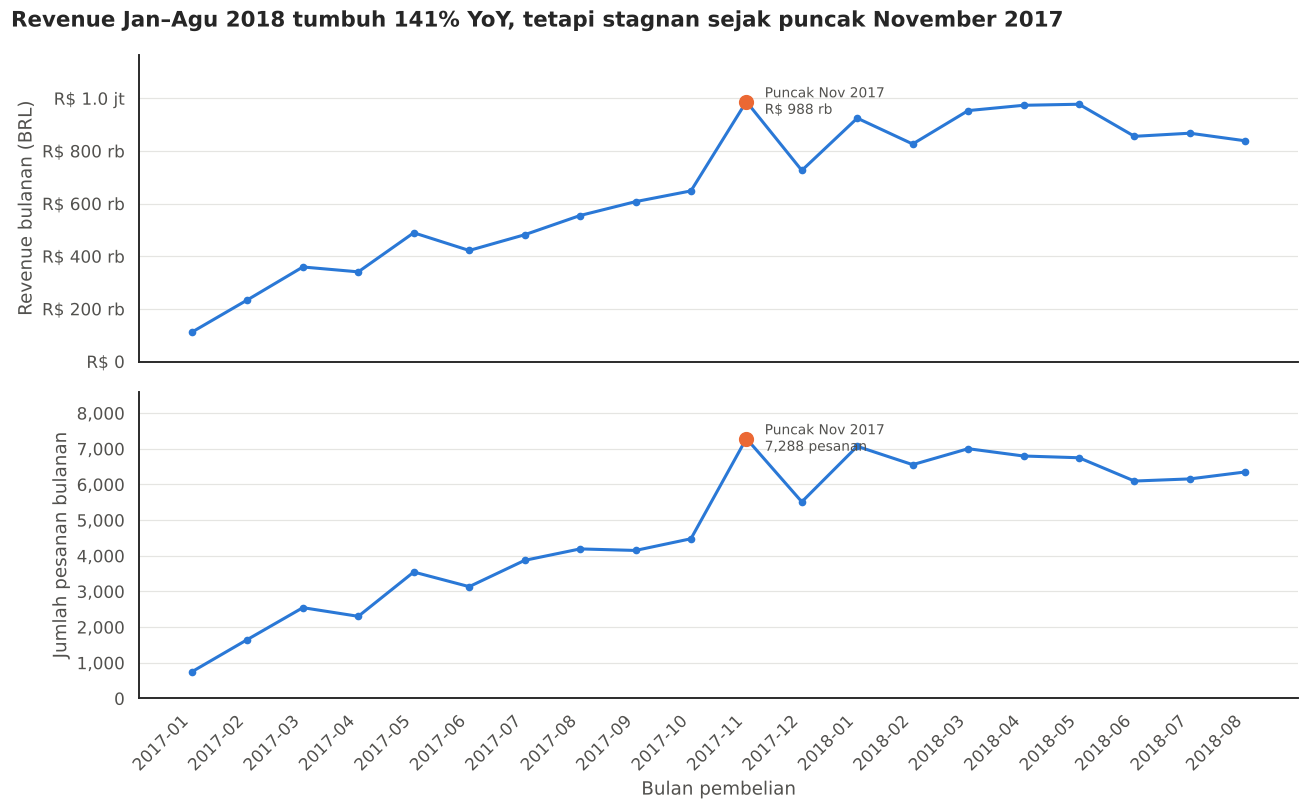

In [34]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
x = np.arange(len(monthly_df))
peak = monthly_df['revenue'].values.argmax()

# Revenue (panel atas) dan jumlah pesanan (panel bawah) dipisah agar tidak memakai dua sumbu-y
for ax, col, title, fmt in [(axes[0], 'revenue', 'Revenue bulanan (BRL)', mtick.FuncFormatter(rupiah_brl)),
                            (axes[1], 'order_count', 'Jumlah pesanan bulanan', mtick.StrMethodFormatter('{x:,.0f}'))]:
    y = monthly_df[col].values
    ax.plot(x, y, color=HIGHLIGHT, linewidth=2, marker='o', markersize=4)
    ax.scatter(x[peak], y[peak], s=80, color=ACCENT, zorder=3)
    ax.annotate(f'Puncak Nov 2017\n{rupiah_brl(y[peak]) if col == "revenue" else f"{y[peak]:,.0f} pesanan"}',
                (x[peak], y[peak]), xytext=(12, -8), textcoords='offset points', color=TEXT, fontsize=9)
    ax.set_ylim(0, y.max() * 1.18)
    ax.yaxis.set_major_formatter(fmt)
    ax.set_ylabel(title)
    ax.grid(axis='y', color='#e5e5e2', linewidth=0.8)

axes[1].set_xticks(x)
axes[1].set_xticklabels(monthly_df.index, rotation=45, ha='right')
axes[1].set_xlabel('Bulan pembelian')
fig.suptitle(f'Revenue Jan–Agu 2018 tumbuh {ytd_growth:.0f}% YoY, tetapi stagnan sejak puncak November 2017',
             fontweight='bold', fontsize=14, x=0.01, ha='left')
plt.tight_layout()
plt.show()

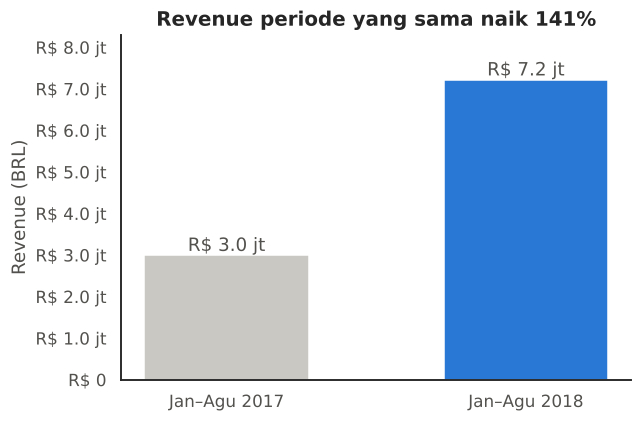

In [35]:
fig, ax = plt.subplots(figsize=(6, 4))
vals = ytd['revenue'].values
bars = ax.bar(['Jan–Agu 2017', 'Jan–Agu 2018'], vals, color=[MUTED, HIGHLIGHT], width=0.55)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v, rupiah_brl(v), ha='center', va='bottom', color=TEXT)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(rupiah_brl))
ax.set_ylim(0, vals.max() * 1.15)
ax.set_ylabel('Revenue (BRL)')
ax.set_title(f'Revenue periode yang sama naik {ytd_growth:.0f}%')
plt.tight_layout()
plt.show()

**Insight:**
- Revenue naik dari ~R$ 0,1 juta (Jan 2017) menjadi puncak **~R$ 1,0 juta pada November 2017**, didorong lonjakan pesanan saat Black Friday.
- Jan–Agu 2018 menghasilkan revenue ~2,4 kali lipat periode yang sama di 2017, tetapi kurva 2018 mendatar di sekitar 6–7 ribu pesanan per bulan — pertumbuhan mulai melambat.

### Pertanyaan 2: Kategori produk apa yang menyumbang revenue terbesar dan terkecil, dan berapa kontribusi 10 kategori teratas?

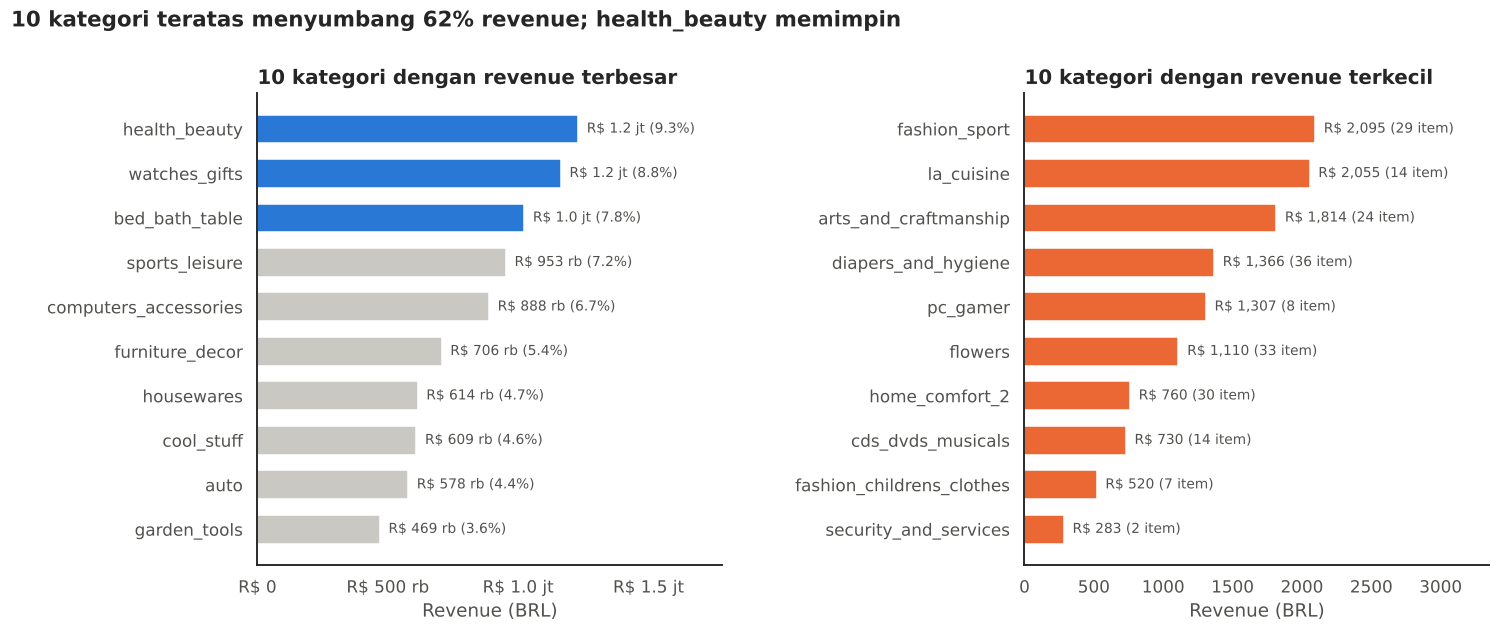

In [36]:
top10 = category_df_agg.head(10).iloc[::-1]
bottom10 = category_df_agg.tail(10).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={'wspace': 0.65})
colors_top = [MUTED] * 7 + [HIGHLIGHT] * 3          # 3 teratas disorot
axes[0].barh(top10.index, top10['revenue'], color=colors_top, height=0.65)
for i, (v, s) in enumerate(zip(top10['revenue'], top10['share_%'])):
    axes[0].text(v, i, f'  {rupiah_brl(v)} ({s:.1f}%)', va='center', fontsize=9, color=TEXT)
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(rupiah_brl))
axes[0].xaxis.set_major_locator(mtick.MaxNLocator(4))
axes[0].set_xlim(0, top10['revenue'].max() * 1.45)
axes[0].set_title('10 kategori dengan revenue terbesar', loc='left')
axes[0].set_xlabel('Revenue (BRL)')

axes[1].barh(bottom10.index, bottom10['revenue'], color=ACCENT, height=0.65)
for i, (v, n) in enumerate(zip(bottom10['revenue'], bottom10['items_sold'])):
    axes[1].text(v, i, f'  R$ {v:,.0f} ({n} item)', va='center', fontsize=9, color=TEXT)
axes[1].set_xlim(0, bottom10['revenue'].max() * 1.6)
axes[1].set_title('10 kategori dengan revenue terkecil', loc='left')
axes[1].set_xlabel('Revenue (BRL)')

fig.suptitle(f"10 kategori teratas menyumbang {category_df_agg['share_%'].head(10).sum():.0f}% revenue; "
             "health_beauty memimpin", fontweight='bold', fontsize=14, x=0.01, ha='left')
plt.subplots_adjust(top=0.85, left=0.17, right=0.97)
plt.show()

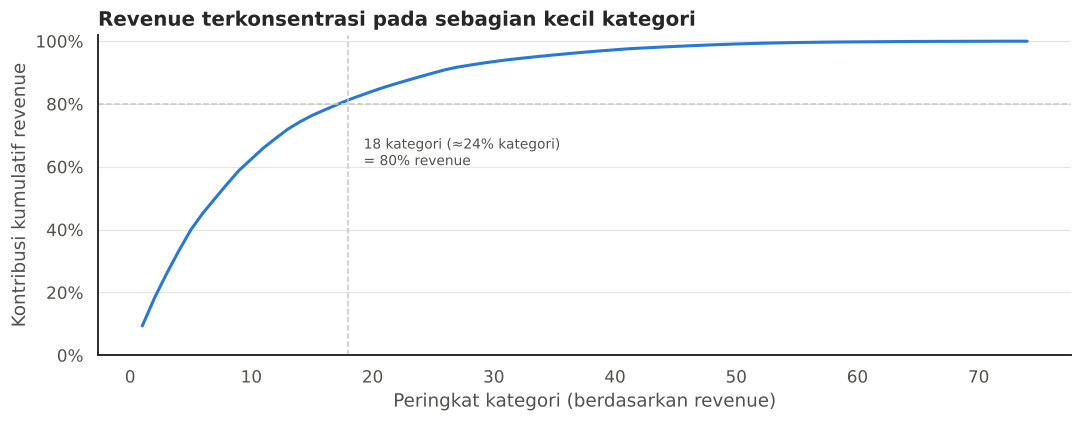

In [37]:
# Kurva Pareto: kontribusi kumulatif revenue berdasarkan peringkat kategori
cum_share = category_df_agg['share_%'].cumsum().values
rank = np.arange(1, len(cum_share) + 1)
n80 = int(np.argmax(cum_share >= 80)) + 1

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(rank, cum_share, color=HIGHLIGHT, linewidth=2)
ax.axhline(80, color=MUTED, linestyle='--', linewidth=1)
ax.axvline(n80, color=MUTED, linestyle='--', linewidth=1)
ax.annotate(f'{n80} kategori (≈{n80/len(rank)*100:.0f}% kategori)\n= 80% revenue', (n80, 80),
            xytext=(10, -40), textcoords='offset points', color=TEXT, fontsize=9)
ax.set_ylim(0, 102)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Peringkat kategori (berdasarkan revenue)')
ax.set_ylabel('Kontribusi kumulatif revenue')
ax.set_title('Revenue terkonsentrasi pada sebagian kecil kategori', loc='left')
ax.grid(axis='y', color='#e5e5e2', linewidth=0.8)
plt.tight_layout()
plt.show()

**Insight:**
- `health_beauty` (~9%), `watches_gifts` (~9%), dan `bed_bath_table` (~8%) adalah tiga kategori dengan revenue terbesar; 10 kategori teratas menyumbang **~62,5%** revenue.
- Pola Pareto terlihat jelas: hanya 18 dari 74 kategori (±24%) yang menghasilkan 80% revenue.
- Kategori terbawah hanya menghasilkan ratusan BRL dari segelintir item — kontribusinya hampir nol.

### Pertanyaan 3: Seberapa besar selisih skor review pesanan terlambat vs tepat waktu, dan state mana yang paling sering terlambat?

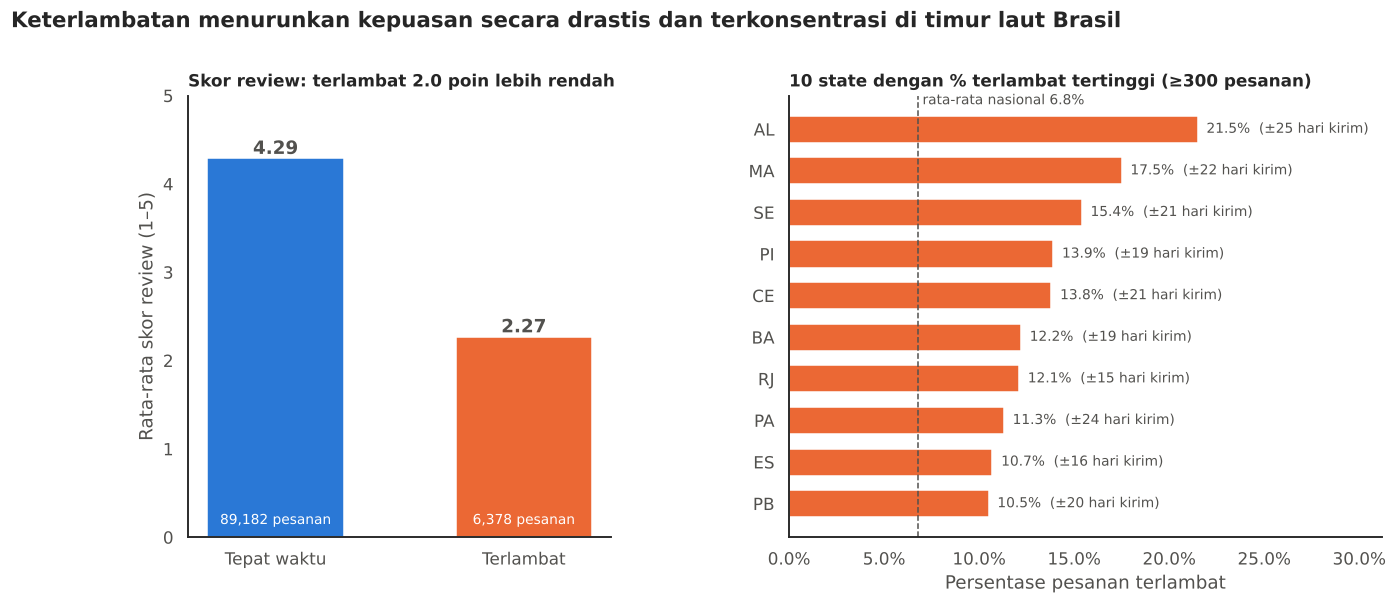

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 1.4], 'wspace': 0.35})

# (a) rata-rata skor review
vals = late_review['mean']
bars = axes[0].bar(vals.index, vals.values, color=[HIGHLIGHT, ACCENT], width=0.55)
for b, v, n in zip(bars, vals.values, late_review['count']):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.05, f'{v:.2f}', ha='center', fontweight='bold', color=TEXT)
    axes[0].text(b.get_x() + b.get_width() / 2, 0.15, f'{n:,} pesanan', ha='center', color='white', fontsize=9)
axes[0].set_ylim(0, 5)
axes[0].set_ylabel('Rata-rata skor review (1–5)')
diff = vals['Tepat waktu'] - vals['Terlambat']
axes[0].set_title(f'Skor review: terlambat {diff:.1f} poin lebih rendah', loc='left', fontsize=11)

# (b) 10 state dengan tingkat keterlambatan tertinggi (min. 300 pesanan agar stabil)
st = state_late[state_late['order_count'] >= 300].head(10).iloc[::-1]
overall_late = order_level['is_late'].mean() * 100
axes[1].barh(st.index, st['late_rate'], color=ACCENT, height=0.65)
axes[1].axvline(overall_late, color=TEXT, linestyle='--', linewidth=1)
axes[1].text(overall_late, len(st) - 0.4, f' rata-rata nasional {overall_late:.1f}%', color=TEXT, fontsize=9)
for i, (v, d) in enumerate(zip(st['late_rate'], st['avg_delivery_days'])):
    axes[1].text(v, i, f'  {v:.1f}%  (±{d:.0f} hari kirim)', va='center', fontsize=9, color=TEXT)
axes[1].set_xlim(0, st['late_rate'].max() * 1.45)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_xlabel('Persentase pesanan terlambat')
axes[1].set_title('10 state dengan % terlambat tertinggi (≥300 pesanan)', loc='left', fontsize=11)

fig.suptitle('Keterlambatan menurunkan kepuasan secara drastis dan terkonsentrasi di timur laut Brasil',
             fontweight='bold', fontsize=14, x=0.01, ha='left')
plt.subplots_adjust(top=0.84)
plt.show()

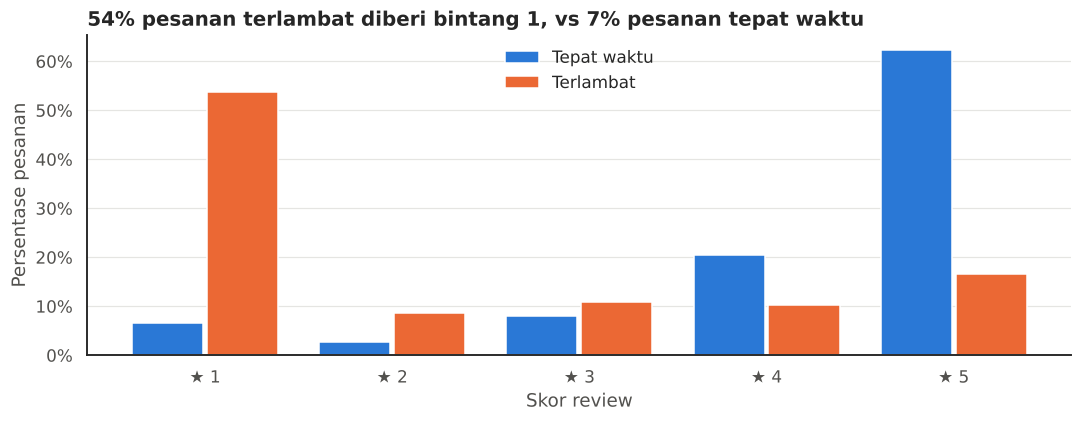

In [39]:
dist = pd.crosstab(order_level['is_late'], order_level['review_score'], normalize='index').mul(100)
dist.index = ['Tepat waktu', 'Terlambat']

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.38
xs = np.arange(1, 6)
ax.bar(xs - width/2 - 0.01, dist.loc['Tepat waktu'], width, color=HIGHLIGHT, label='Tepat waktu')
ax.bar(xs + width/2 + 0.01, dist.loc['Terlambat'], width, color=ACCENT, label='Terlambat')
ax.set_xticks(xs)
ax.set_xticklabels([f'★ {i}' for i in xs])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Persentase pesanan')
ax.set_xlabel('Skor review')
ax.set_title(f"{dist.loc['Terlambat', 1]:.0f}% pesanan terlambat diberi bintang 1, vs "
             f"{dist.loc['Tepat waktu', 1]:.0f}% pesanan tepat waktu", loc='left')
ax.legend(frameon=False)
ax.grid(axis='y', color='#e5e5e2', linewidth=0.8)
plt.tight_layout()
plt.show()

**Insight:**
- Pesanan terlambat memiliki rata-rata skor review **2,27**, sedangkan pesanan tepat waktu **4,29**. Lebih dari separuh (54%) pesanan terlambat diberi bintang 1.
- Keterlambatan tertinggi terjadi di state **AL, MA, PI, CE, SE, BA, RJ** — sebagian besar di wilayah timur laut yang jauh dari pusat penjual di SP, dengan waktu kirim rata-rata sekitar 3 minggu, kira-kira dua kali lipat SP (±9 hari).

## Analisis Lanjutan (Opsional)

Tiga teknik analisis lanjutan **tanpa algoritma machine learning** diterapkan untuk memperkaya jawaban pertanyaan bisnis:

1. **RFM Analysis** — mengelompokkan pelanggan (`customer_unique_id`) berdasarkan *Recency* (hari sejak pembelian terakhir), *Frequency* (jumlah pesanan), dan *Monetary* (total belanja) untuk menentukan strategi retensi.
2. **Clustering dengan Manual Grouping & Binning** — membuat segmen pelanggan dari skor RFM dengan aturan bisnis, serta mengelompokkan lama pengiriman ke dalam interval (`pd.cut`) untuk melihat ambang waktu kirim yang mulai menurunkan kepuasan.
3. **Geospatial Analysis** — memetakan sebaran pelanggan, revenue, dan tingkat keterlambatan per state menggunakan koordinat dari tabel `geolocation` dan library **folium**.

### 1. RFM Analysis

Tanggal acuan (*snapshot date*) adalah satu hari setelah tanggal pembelian terakhir dalam periode analisis. Skor R dan M dihitung dengan kuantil (1–5, makin besar makin baik). Karena ~97% pelanggan hanya bertransaksi sekali, skor F tidak bisa dibagi kuantil sehingga memakai **binning berbasis aturan**: 1 pesanan = 1, 2 pesanan = 3, ≥3 pesanan = 5.

In [40]:
snapshot_date = all_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
rfm_df = (all_df.groupby('customer_unique_id')
          .agg(last_purchase=('order_purchase_timestamp', 'max'),
               frequency=('order_id', 'nunique'),
               monetary=('price', 'sum')))
rfm_df['recency'] = (snapshot_date - rfm_df['last_purchase']).dt.days
rfm_df = rfm_df.drop(columns='last_purchase')
print('Snapshot date:', snapshot_date.date(), '| jumlah pelanggan unik:', len(rfm_df))
rfm_df.describe().round(2)

Snapshot date: 2018-08-30 | jumlah pelanggan unik: 93096


,frequency,monetary,recency
count,93096.00,93096.00,93096.00
mean,1.03,141.57,236.71
std,0.21,215.77,150.94
min,1.00,0.85,1.00
25%,1.00,47.65,114.00
50%,1.00,89.70,218.00
75%,1.00,154.16,345.00
max,15.00,13440.00,602.00


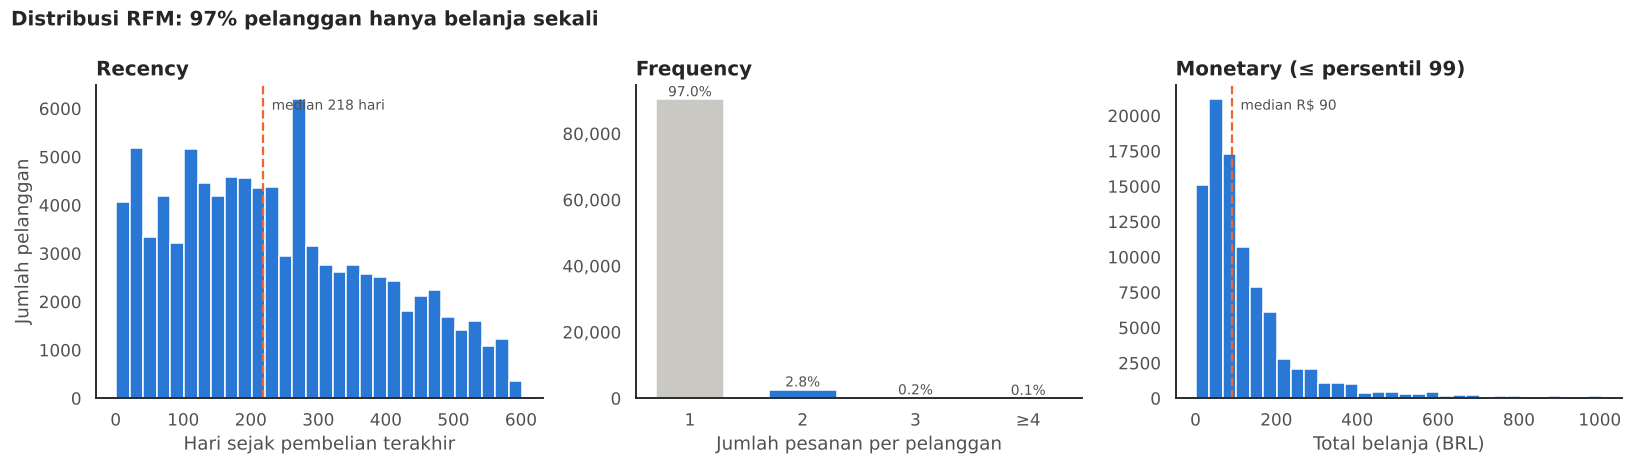

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# Recency
axes[0].hist(rfm_df['recency'], bins=30, color=HIGHLIGHT, edgecolor='white')
axes[0].axvline(rfm_df['recency'].median(), color=ACCENT, linestyle='--', linewidth=1.5)
axes[0].text(rfm_df['recency'].median(), axes[0].get_ylim()[1] * 0.92,
             f"  median {rfm_df['recency'].median():.0f} hari", color=TEXT, fontsize=9)
axes[0].set_title('Recency', loc='left'); axes[0].set_xlabel('Hari sejak pembelian terakhir')
axes[0].set_ylabel('Jumlah pelanggan')

# Frequency (dikelompokkan karena sangat menceng)
freq = pd.cut(rfm_df['frequency'], bins=[0, 1, 2, 3, np.inf], labels=['1', '2', '3', '≥4']).value_counts().sort_index()
bars = axes[1].bar(freq.index.astype(str), freq.values, color=[MUTED, HIGHLIGHT, HIGHLIGHT, HIGHLIGHT], width=0.6)
for bar, v in zip(bars, freq.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v, f'{v/len(rfm_df)*100:.1f}%', ha='center', va='bottom',
                 fontsize=9, color=TEXT)
axes[1].set_title('Frequency', loc='left'); axes[1].set_xlabel('Jumlah pesanan per pelanggan')
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

# Monetary (dipotong di persentil 99 agar distribusi terbaca)
p99 = rfm_df['monetary'].quantile(0.99)
axes[2].hist(rfm_df.loc[rfm_df['monetary'] <= p99, 'monetary'], bins=30, color=HIGHLIGHT, edgecolor='white')
axes[2].axvline(rfm_df['monetary'].median(), color=ACCENT, linestyle='--', linewidth=1.5)
axes[2].text(rfm_df['monetary'].median(), axes[2].get_ylim()[1] * 0.92,
             f"  median R$ {rfm_df['monetary'].median():.0f}", color=TEXT, fontsize=9)
axes[2].set_title('Monetary (≤ persentil 99)', loc='left'); axes[2].set_xlabel('Total belanja (BRL)')

fig.suptitle(f"Distribusi RFM: {freq.iloc[0]/len(rfm_df)*100:.0f}% pelanggan hanya belanja sekali",
             fontweight='bold', fontsize=13, x=0.01, ha='left')
plt.tight_layout()
plt.show()

### 2. Clustering: Manual Grouping (segmen RFM) & Binning (lama pengiriman)

In [42]:
rfm_df['R_score'] = pd.qcut(rfm_df['recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_df['M_score'] = pd.qcut(rfm_df['monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm_df['F_score'] = pd.cut(rfm_df['frequency'], bins=[0, 1, 2, np.inf], labels=[1, 3, 5]).astype(int)

def rfm_segment(row):
    """Manual grouping berdasarkan aturan bisnis."""
    if row['F_score'] >= 3 and row['R_score'] >= 4:
        return 'Champions'
    if row['F_score'] >= 3:
        return 'Loyal Customers'
    if row['R_score'] >= 4 and row['M_score'] >= 4:
        return 'New Big Spenders'
    if row['R_score'] >= 4:
        return 'New Customers'
    if row['R_score'] <= 2 and row['M_score'] >= 4:
        return 'At Risk (High Value)'
    if row['R_score'] <= 2:
        return 'Hibernating'
    return 'Need Attention'

rfm_df['segment'] = rfm_df.apply(rfm_segment, axis=1)
segment_summary = (rfm_df.groupby('segment')
                   .agg(customers=('recency', 'size'), avg_recency=('recency', 'mean'),
                        avg_frequency=('frequency', 'mean'), avg_monetary=('monetary', 'mean'),
                        total_monetary=('monetary', 'sum'))
                   .sort_values('customers', ascending=False))
segment_summary['customers_%'] = (segment_summary['customers'] / len(rfm_df) * 100).round(1)
segment_summary.round(2)

,customers,avg_recency,avg_frequency,avg_monetary,total_monetary,customers_%
segment,,,,,,
Hibernating,22437,393.74,1.00,56.00,1256490.78,24.1
New Customers,21773,89.82,1.00,55.70,1212800.06,23.4
Need Attention,18106,220.46,1.00,129.80,2350181.26,19.4
New Big Spenders,14449,91.85,1.00,267.82,3869732.04,15.5
At Risk (High Value),13542,392.53,1.00,278.04,3765218.77,14.5
Loyal Customers,1584,318.90,2.08,252.30,399650.45,1.7
Champions,1205,89.06,2.15,270.29,325704.59,1.3


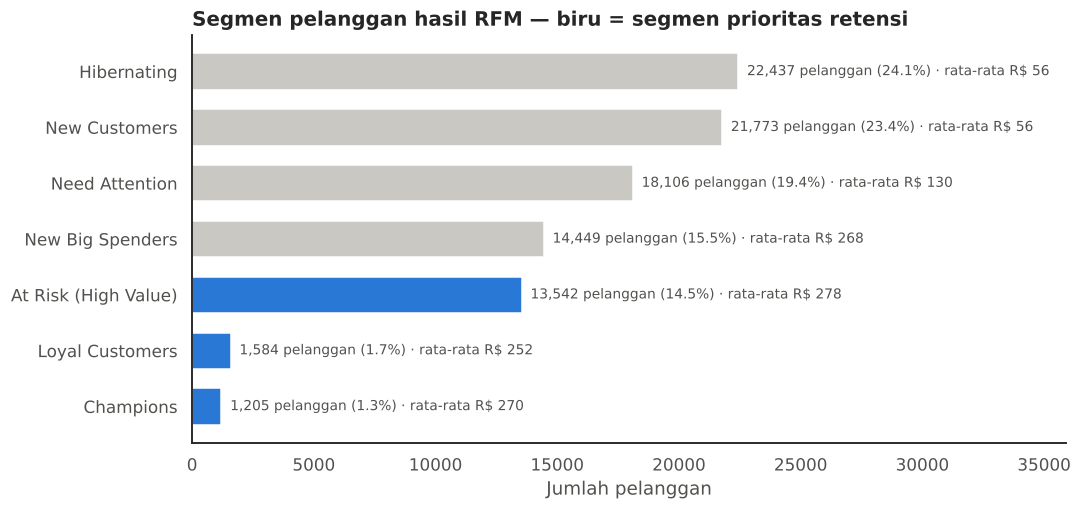

In [43]:
seg = segment_summary.sort_values('customers')
priority = {'At Risk (High Value)', 'Champions', 'Loyal Customers'}
colors = [HIGHLIGHT if s in priority else MUTED for s in seg.index]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(seg.index, seg['customers'], color=colors, height=0.65)
for i, (n, p, m) in enumerate(zip(seg['customers'], seg['customers_%'], seg['avg_monetary'])):
    ax.text(n, i, f'  {n:,} pelanggan ({p}%) · rata-rata R$ {m:,.0f}', va='center', fontsize=9, color=TEXT)
ax.set_xlim(0, seg['customers'].max() * 1.6)
ax.set_xlabel('Jumlah pelanggan')
ax.set_title('Segmen pelanggan hasil RFM — biru = segmen prioritas retensi', loc='left')
plt.tight_layout()
plt.show()

Selanjutnya **binning** lama pengiriman dengan `pd.cut` untuk melihat pada interval berapa hari kepuasan pelanggan mulai turun tajam.

In [44]:
bins = [0, 7, 14, 21, 30, np.inf]
labels = ['≤7 hari', '8–14 hari', '15–21 hari', '22–30 hari', '>30 hari']
order_level = order_level.copy()
order_level['delivery_bin'] = pd.cut(order_level['delivery_days'], bins=bins, labels=labels)
bin_summary = (order_level.groupby('delivery_bin', observed=True)
               .agg(orders=('order_id', 'nunique'), avg_review=('review_score', 'mean'),
                    late_rate=('is_late', 'mean')))
bin_summary['orders_%'] = (bin_summary['orders'] / bin_summary['orders'].sum() * 100).round(1)
bin_summary.round(2)

,orders,avg_review,late_rate,orders_%
delivery_bin,,,,
≤7 hari,26038,4.42,0.00,27.1
8–14 hari,40111,4.31,0.01,41.7
15–21 hari,17653,4.14,0.03,18.3
22–30 hari,7899,3.61,0.26,8.2
>30 hari,4502,2.24,0.79,4.7


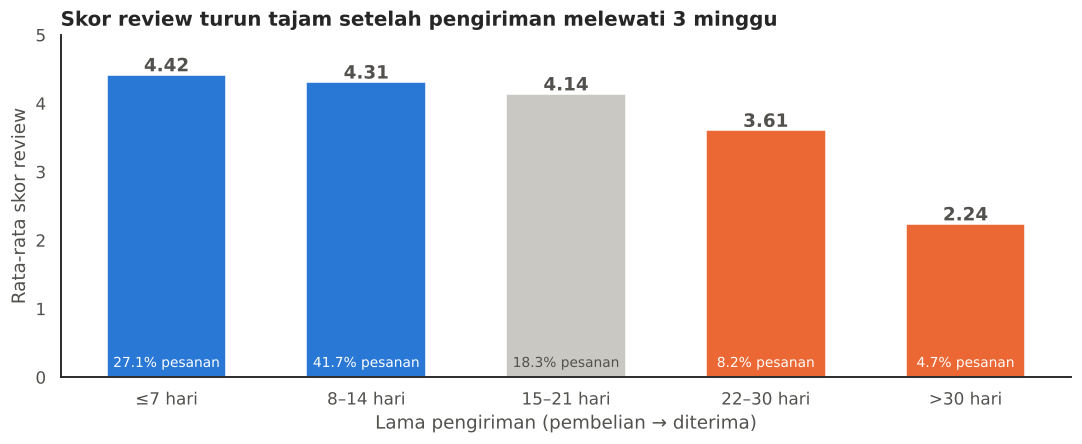

In [45]:
fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [HIGHLIGHT, HIGHLIGHT, MUTED, ACCENT, ACCENT]
bars = ax.bar(bin_summary.index.astype(str), bin_summary['avg_review'], color=colors, width=0.6)
for b, v, p, c in zip(bars, bin_summary['avg_review'], bin_summary['orders_%'], colors):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.05, f'{v:.2f}', ha='center', fontweight='bold', color=TEXT)
    ax.text(b.get_x() + b.get_width() / 2, 0.15, f'{p}% pesanan', ha='center',
            color=TEXT if c == MUTED else 'white', fontsize=9)
ax.set_ylim(0, 5)
ax.set_ylabel('Rata-rata skor review')
ax.set_xlabel('Lama pengiriman (pembelian → diterima)')
ax.set_title('Skor review turun tajam setelah pengiriman melewati 3 minggu', loc='left')
plt.tight_layout()
plt.show()

### 3. Geospatial Analysis

In [46]:
state_geo = (all_df.groupby('customer_state')
             .agg(customers=('customer_unique_id', 'nunique'), revenue=('price', 'sum'),
                  lat=('lat', 'median'), lng=('lng', 'median'))
             .join(state_late[['late_rate', 'avg_delivery_days', 'avg_review']])
             .sort_values('revenue', ascending=False))
state_geo['revenue_%'] = (state_geo['revenue'] / state_geo['revenue'].sum() * 100).round(1)
state_geo.round(2).head(10)

,customers,revenue,lat,lng,late_rate,avg_delivery_days,avg_review,revenue_%
customer_state,,,,,,,,
SP,39058,5054516.95,-23.51,-46.69,4.5,8.74,4.25,38.4
RJ,11879,1751433.85,-22.89,-43.25,12.1,15.30,3.97,13.3
MG,10969,1548206.88,-19.93,-43.98,4.6,11.98,4.19,11.7
RS,5150,726194.92,-29.89,-51.23,6.1,15.29,4.19,5.5
PR,4750,664048.00,-25.39,-50.23,4.1,11.97,4.24,5.0
SC,3441,504774.07,-27.15,-49.01,8.2,14.95,4.13,3.8
BA,3155,493339.26,-12.95,-38.76,12.2,19.33,3.93,3.7
DF,2013,295454.64,-15.82,-47.95,5.7,12.94,4.13,2.2
GO,1889,281932.21,-16.69,-49.26,6.6,15.61,4.10,2.1


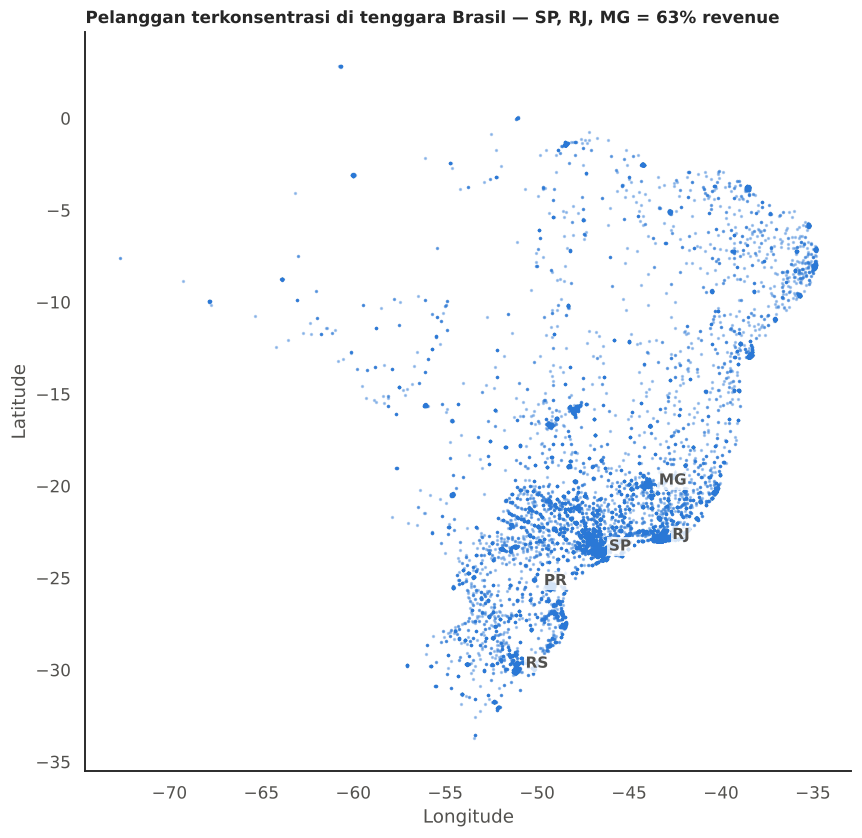

In [47]:
# Peta statis sebaran pelanggan (sampel 30 ribu titik agar ringan)
pts = all_df.drop_duplicates('customer_unique_id').dropna(subset=['lat', 'lng']).sample(30000, random_state=42)
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(pts['lng'], pts['lat'], s=1.5, alpha=0.35, color=HIGHLIGHT)
for st_name, r in state_geo.head(5).iterrows():
    ax.text(r['lng'] + 0.6, r['lat'], st_name, fontsize=10, fontweight='bold', color=TEXT,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1))
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title(f"Pelanggan terkonsentrasi di tenggara Brasil — SP, RJ, MG = "
             f"{state_geo['revenue_%'].head(3).sum():.0f}% revenue", loc='left', fontsize=11)
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

In [48]:
# Peta interaktif folium: ukuran lingkaran = revenue, warna = tingkat keterlambatan
m = folium.Map(location=[-14.5, -52], zoom_start=4, tiles='OpenStreetMap')
max_rev = state_geo['revenue'].max()
for st_name, r in state_geo.iterrows():
    color = ACCENT if r['late_rate'] > overall_late else HIGHLIGHT
    folium.CircleMarker(
        location=[r['lat'], r['lng']],
        radius=5 + 30 * np.sqrt(r['revenue'] / max_rev),
        color=color, fill=True, fill_color=color, fill_opacity=0.55, weight=1,
        tooltip=(f"<b>{st_name}</b><br>Revenue: R$ {r['revenue']:,.0f} ({r['revenue_%']}%)<br>"
                 f"Pelanggan: {r['customers']:,}<br>Terlambat: {r['late_rate']:.1f}%<br>"
                 f"Rata-rata kirim: {r['avg_delivery_days']:.1f} hari<br>Skor review: {r['avg_review']:.2f}")
    ).add_to(m)
legend_html = (f"<div style='position:fixed;bottom:20px;left:20px;z-index:999;background:white;padding:8px 10px;"
               f"border:1px solid #ccc;font-size:12px'><b>Ukuran</b> = revenue<br>"
               f"<span style='color:{ACCENT}'>●</span> keterlambatan &gt; rata-rata ({overall_late:.1f}%)<br>"
               f"<span style='color:{HIGHLIGHT}'>●</span> keterlambatan ≤ rata-rata</div>")
m.get_root().html.add_child(folium.Element(legend_html))
m

**Insight:**
- **RFM**: ~97% pelanggan hanya bertransaksi sekali. Segmen `At Risk (High Value)` berisi ±13,5 ribu pelanggan (14,5%) dengan rata-rata belanja ±R$ 278 yang sudah lebih dari setahun tidak kembali — target utama kampanye *win-back*. `Champions` & `Loyal Customers` hanya ±3% pelanggan, tetapi merupakan satu-satunya kelompok yang belanja berulang.
- **Binning**: pesanan yang tiba ≤14 hari (±69% pesanan) mendapat skor 4,3–4,4, sedangkan pengiriman 22–30 hari turun ke 3,6 dan >30 hari hanya 2,2. Ambang kritisnya adalah **±3 minggu**.
- **Geospatial**: revenue sangat terkonsentrasi di tenggara (SP, RJ, MG ≈ 63%). Lingkaran oranye (keterlambatan di atas rata-rata) didominasi state timur laut dan RJ, menunjukkan masalah jarak & jaringan logistik dari pusat penjual.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Revenue bulanan tumbuh pesat sepanjang 2017 hingga mencapai puncak di November 2017 (~R$ 1,0 juta, efek Black Friday). Revenue Jan–Agu 2018 tumbuh **sekitar 141%** (R$ 3,0 juta → R$ 7,2 juta) dibanding Jan–Agu 2017, namun sepanjang 2018 tren pesanan dan revenue cenderung **datar (plateau)** di ±6–7 ribu pesanan per bulan.
- **Conclusion pertanyaan 2:** `health_beauty`, `watches_gifts`, dan `bed_bath_table` adalah kategori dengan revenue terbesar, dan **10 kategori teratas menyumbang ~62,5% total revenue** (pola Pareto: 18 dari 74 kategori = 80% revenue). Kategori terkecil seperti `security_and_services`, `fashion_childrens_clothes`, dan `cds_dvds_musicals` hanya menghasilkan ratusan BRL.
- **Conclusion pertanyaan 3:** Pesanan terlambat (6,8% dari total) memiliki rata-rata skor review **2,27 vs 4,29** untuk pesanan tepat waktu (selisih ±2 poin). Keterlambatan tertinggi terjadi di state timur laut (**AL 21,5%, MA 17,5%, SE 15,4%, PI 13,9%, CE 13,8%**), 2–3 kali rata-rata nasional.

**Rekomendasi Action Item:**
- **Siapkan kampanye & kapasitas puncak November** (Black Friday) lebih awal — stok kategori teratas, kapasitas gudang, dan kurir — serta luncurkan promo tematik di bulan-bulan 2018 yang datar untuk memecah *plateau*.
- **Prioritaskan anggaran pemasaran dan ketersediaan stok** pada 10 kategori teratas (terutama `health_beauty`, `watches_gifts`, `bed_bath_table`); evaluasi ulang kategori berkinerja sangat rendah (bundling atau dihentikan).
- **Perbaiki logistik ke wilayah timur laut**: tambahkan mitra kurir/gudang regional atau rekrut penjual lokal di AL, MA, PI, CE, SE, dan buat estimasi pengiriman yang lebih realistis; targetkan pesanan tiba **< 21 hari** karena di atas ambang ini skor review anjlok.
- **Jalankan kampanye win-back** (voucher personal) untuk segmen `At Risk (High Value)` dan program loyalitas untuk `Champions`/`Loyal Customers`, karena hampir semua pelanggan saat ini hanya membeli sekali.

**Ekspor data untuk dashboard**

In [49]:
main_cols = ['order_id', 'order_item_id', 'customer_unique_id', 'customer_city', 'customer_state', 'lat', 'lng',
             'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date',
             'delivery_days', 'is_late', 'product_category', 'price', 'freight_value', 'review_score']
main_data = all_df[main_cols].copy()
main_data['delivery_days'] = main_data['delivery_days'].round(2)
main_data[['lat', 'lng']] = main_data[['lat', 'lng']].round(4)
main_data.to_csv('dashboard/main_data.csv', index=False)
print(main_data.shape)

(109872, 16)
